# WGAN sur Fashion-MNIST

Ce notebook présente l’implémentation d’un Wasserstein Generative Adversarial Network (WGAN) sur le dataset Fashion-MNIST, dans le but de générer des images réalistes et de comparer ensuite les résultats avec ceux d’un Score-Based Generative Model (SGM).

## Import

In [3]:
# Imports and setup
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import random
from google.colab import drive
import torch
import os
from PIL import Image

## Configuration

In [21]:
# Hyperparameters

SEED = 42

# Dataset
batch_size = 64
image_size = 28
num_channels = 1
num_classes = 10

# Latent vector
z_dim = 100

# Training
lr = 5e-5
n_epochs = 30
n_critic = 5
clip_value = 0.01

# Loader
num_workers = 2
pin_memory = torch.cuda.is_available()

# Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Chargement de Fashion-MNIST

In [22]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # ici on normalise pour centrer les données entre [-1,1]
])

# Données d'entrainement
train_dataset = torchvision.datasets.FashionMNIST(
    root="./data/FashionMNIST",
    train=True,
    download=True,
    transform=transform
)

# données de tests
test_dataset = torchvision.datasets.FashionMNIST(
    root="./data/FashionMNIST",
    train=False,
    download=True,
    transform=transform
)

print("Train size :", len(train_dataset))
print("Test size :", len(test_dataset))

Train size : 60000
Test size : 10000


## Préparation des DataLoaders



In [23]:
# dataloader des données d'entraînement, de validation et de test

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin_memory
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin_memory
)

## Vérifier la forme des données

In [24]:
images, labels = next(iter(train_loader))
print("Shape des images :", images[0,0,:,:].shape)
print("Shape des labels :", labels.shape)

Shape des images : torch.Size([28, 28])
Shape des labels : torch.Size([64])


## Affichage de quelques images

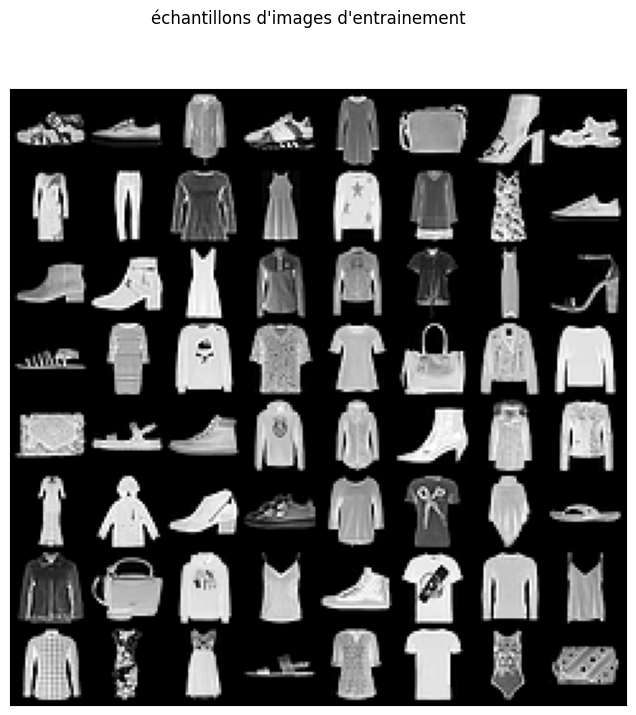

tensor([5, 7, 4, 7, 3, 8, 9, 5, 3, 1, 2, 3, 2, 3, 3, 7, 9, 9, 3, 2, 4, 6, 3, 5,
        5, 3, 2, 0, 0, 8, 4, 2, 8, 5, 9, 2, 4, 9, 4, 4, 3, 4, 9, 7, 2, 0, 4, 5,
        4, 8, 2, 6, 7, 0, 2, 0, 6, 3, 3, 5, 6, 0, 0, 8])


In [25]:
def show_images(img,title):
    plt.figure(figsize=(8, 8))
    plt.imshow(np.transpose(img, (1, 2, 0)))
    plt.xticks(())
    plt.yticks(())
    plt.suptitle(title)
    plt.show()

show_images(torchvision.utils.make_grid(images*0.5 + 0.5),"échantillons d'images d'entrainement")
print(labels)

## Générateur

In [26]:
# Generator: 3 blocks + output layer
class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()

        self.net = nn.Sequential(
            # Block 1: [batch, z_dim, 1, 1] -> [batch, 256, 7, 7]
            nn.ConvTranspose2d(z_dim, 256, kernel_size=7, stride=1, padding=0),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            # Block 2: [batch, 256, 7, 7] -> [batch, 128, 14, 14]
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # Block 3: [batch, 128, 14, 14] -> [batch, 64, 28, 28]
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # Output layer: [batch, 64, 28, 28] -> [batch, 1, 28, 28]
            nn.ConvTranspose2d(64, 1, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        return self.net(x)

## Critic

In [27]:
# Critic for WGAN
class Critic(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            # Input: [batch_size, 1, 28, 28]
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),   # -> [64, 14, 14]
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # -> [128, 7, 7]
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1), # -> [256, 3, 3]
            nn.LeakyReLU(0.2, inplace=True),

            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 1)
        )

    def forward(self, x):
        return self.net(x)

## Initialisation

In [28]:
# Initialize models
G = Generator(z_dim=z_dim).to(device)
D = Critic().to(device)

print(G)
print(D)

Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1))
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): Tanh()
  )
)
Critic(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): LeakyReLU(negative_slope=0.

## Optimiseurs RMSprop

In [29]:
# Optimizers
opt_G = optim.RMSprop(G.parameters(), lr=lr)
opt_D = optim.RMSprop(D.parameters(), lr=lr)

## Fonction de bruit

In [30]:
# Noise sampling
def sample_noise(batch_size, z_dim, device):
    return torch.randn(batch_size, z_dim, 1, 1, device=device)

fixed_noise = sample_noise(64, z_dim, device)

## Fonction d'enregistrement des images générées pendant le training

In [31]:
def save_generated_images(generator, fixed_noise, device, epoch, save_dir):
    generator.eval()

    with torch.no_grad():
        fake_images = generator(fixed_noise).cpu()

    fake_images = fake_images * 0.5 + 0.5  # dénormalisation

    grid = torchvision.utils.make_grid(fake_images, nrow=8)

    # créer dossier si besoin
    os.makedirs(save_dir, exist_ok=True)

    # sauvegarde
    save_path = os.path.join(save_dir, f"epoch_{epoch}.png")

    plt.figure(figsize=(8, 8))
    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.xticks(())
    plt.yticks(())
    plt.suptitle(f"WGAN - Epoch {epoch}")
    plt.savefig(save_path, bbox_inches='tight')
    plt.close()

    generator.train()

## Entrainement

In [32]:
def train_wgan():

    G_losses = []
    D_losses = []

    for epoch in range(n_epochs):

        for batch_idx, (real_images, _) in enumerate(train_loader):
            real_images = real_images.to(device)
            current_batch_size = real_images.size(0)

            # -------------------------
            # Train Critic
            # -------------------------
            for _ in range(n_critic):
                z = sample_noise(current_batch_size, z_dim, device)
                fake_images = G(z).detach()

                loss_D = -(D(real_images).mean() - D(fake_images).mean())

                opt_D.zero_grad()
                loss_D.backward()
                opt_D.step()

                # Weight clipping
                for p in D.parameters():
                    p.data.clamp_(-clip_value, clip_value)

            # -------------------------
            # Train Generator
            # -------------------------
            z = sample_noise(current_batch_size, z_dim, device)
            fake_images = G(z)

            loss_G = -D(fake_images).mean()

            opt_G.zero_grad()
            loss_G.backward()
            opt_G.step()

            # Save losses
            G_losses.append(loss_G.item())
            D_losses.append(loss_D.item())

        # -------------------------
        # Logging
        # -------------------------
        print(f"Epoch [{epoch+1}/{n_epochs}] | Loss D: {loss_D.item():.4f} | Loss G: {loss_G.item():.4f}")

        # -------------------------
        # Visualization
        # -------------------------
        if (epoch + 1) % 10 == 0:
            save_generated_images(G, fixed_noise, device, epoch+1, save_dir="generated_images")

    return G_losses, D_losses

In [33]:
# entrainement à faire que si on veut ré-entrainer le modéle
G_losses, D_losses = train_wgan()

Epoch [1/30] | Loss D: -4.0638 | Loss G: 1.6123
Epoch [2/30] | Loss D: -0.5131 | Loss G: 0.5853
Epoch [3/30] | Loss D: -0.3395 | Loss G: 0.9289
Epoch [4/30] | Loss D: -0.2730 | Loss G: 0.2038
Epoch [5/30] | Loss D: -0.0353 | Loss G: -0.7689
Epoch [6/30] | Loss D: -0.1257 | Loss G: -1.5776
Epoch [7/30] | Loss D: -0.2994 | Loss G: 2.0348
Epoch [8/30] | Loss D: -0.1576 | Loss G: 0.2448
Epoch [9/30] | Loss D: -0.0755 | Loss G: -1.3576
Epoch [10/30] | Loss D: -0.1116 | Loss G: -1.9042
Epoch [11/30] | Loss D: -0.1364 | Loss G: -2.2715
Epoch [12/30] | Loss D: -0.9803 | Loss G: 3.0573
Epoch [13/30] | Loss D: -0.3944 | Loss G: -4.6000
Epoch [14/30] | Loss D: -0.5414 | Loss G: 4.3198
Epoch [15/30] | Loss D: 0.8435 | Loss G: 2.5762
Epoch [16/30] | Loss D: -0.3520 | Loss G: -5.9508
Epoch [17/30] | Loss D: 0.2058 | Loss G: 1.0277
Epoch [18/30] | Loss D: -1.1501 | Loss G: 3.2513
Epoch [19/30] | Loss D: -0.1964 | Loss G: 2.0668
Epoch [20/30] | Loss D: -0.8581 | Loss G: -3.4052
Epoch [21/30] | Loss D:

In [34]:
# SAVE MODEL + LOSSES

drive.mount('/content/drive')

save_path = "/content/drive/MyDrive/wgan_results.pth"

torch.save({
    "generator_state_dict": G.state_dict(),
    "critic_state_dict": D.state_dict(),
    "G_losses": G_losses,
    "D_losses": D_losses
}, save_path)

print("Modèle et pertes sauvegardés :", save_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modèle et pertes sauvegardés : /content/drive/MyDrive/wgan_results.pth


In [35]:
# LOAD MODEL + LOSSES à faire que si le modéle à été déjà entrainé et sauvegarder

drive.mount('/content/drive')

load_path = "/content/drive/MyDrive/wgan_results.pth"

checkpoint = torch.load(load_path, map_location=device)

G = Generator(z_dim=z_dim).to(device)
D = Critic().to(device)

G.load_state_dict(checkpoint["generator_state_dict"])
D.load_state_dict(checkpoint["critic_state_dict"])

G_losses = checkpoint["G_losses"]
D_losses = checkpoint["D_losses"]

print("Modèle et pertes chargés")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modèle et pertes chargés


## Affichage des pertes

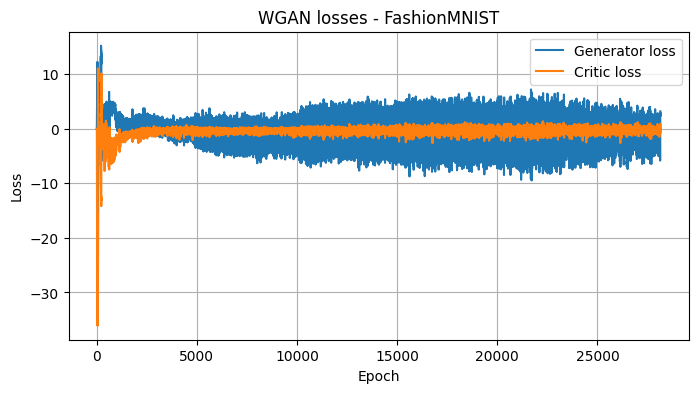

In [36]:
# Plot losses
def plot_losses(G_losses, D_losses, title="Training losses"):
    plt.figure(figsize=(8, 4))
    plt.plot(G_losses, label="Generator loss")
    plt.plot(D_losses, label="Critic loss")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

#Affichage des pertes
plot_losses(G_losses, D_losses, title="WGAN losses - FashionMNIST")

## Evaluation

In [37]:
def evaluate_wgan_random(generator, n=64, title_prefix="Evaluation"):

    generator.eval()

    # Images réelles (test)
    test_images, _ = next(iter(test_loader))
    test_images = test_images[:n].to(device)

    # dénormalisation
    test_images = test_images * 0.5 + 0.5
    real_grid = torchvision.utils.make_grid(test_images.cpu(), nrow=int(n**0.5))
    show_images(real_grid, f"{title_prefix} - Real images")

    # Images générées
    with torch.no_grad():
        z = sample_noise(n, z_dim, device)
        fake_images = generator(z).cpu()

    # dénormalisation
    fake_images = fake_images * 0.5 + 0.5
    fake_grid = torchvision.utils.make_grid(fake_images, nrow=int(n**0.5))
    show_images(fake_grid, f"{title_prefix} - Generated images")

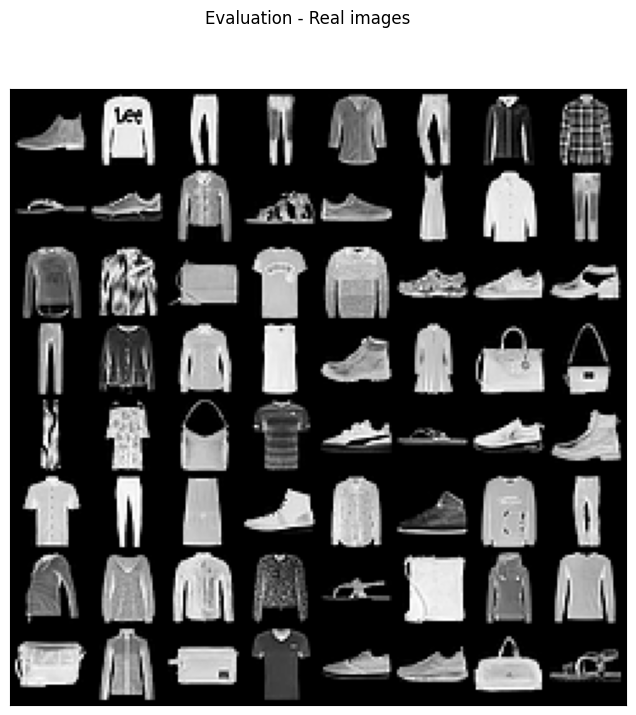

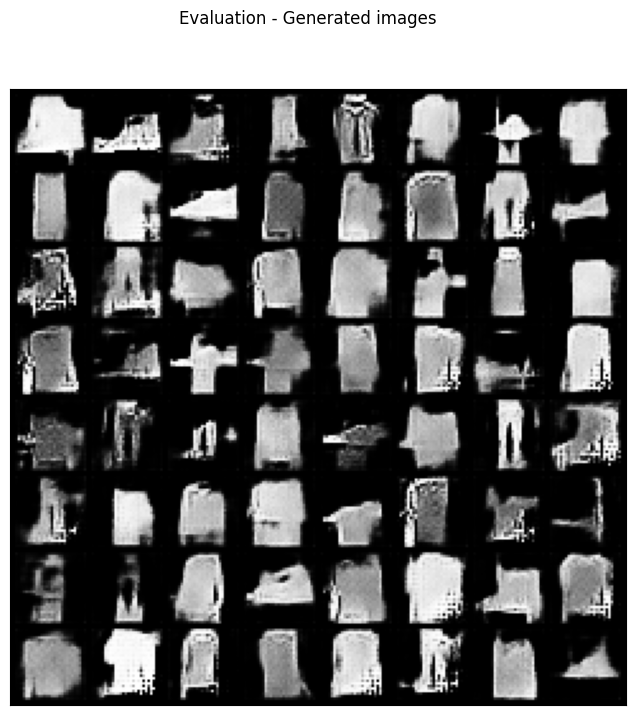

In [38]:
evaluate_wgan_random(G)

## Affichage des images générées entre epochs durant l'entrainement

In [4]:
def show_saved_images(save_dir):
    images = os.listdir(save_dir)

    plt.figure(figsize=(15, 10))

    for i, img_name in enumerate(images):
        img_path = os.path.join(save_dir, img_name)
        img = Image.open(img_path)

        plt.subplot(1, len(images), i + 1)
        plt.imshow(img)
        plt.title(img_name.replace(".png", ""))
        plt.axis("off")

    plt.show()

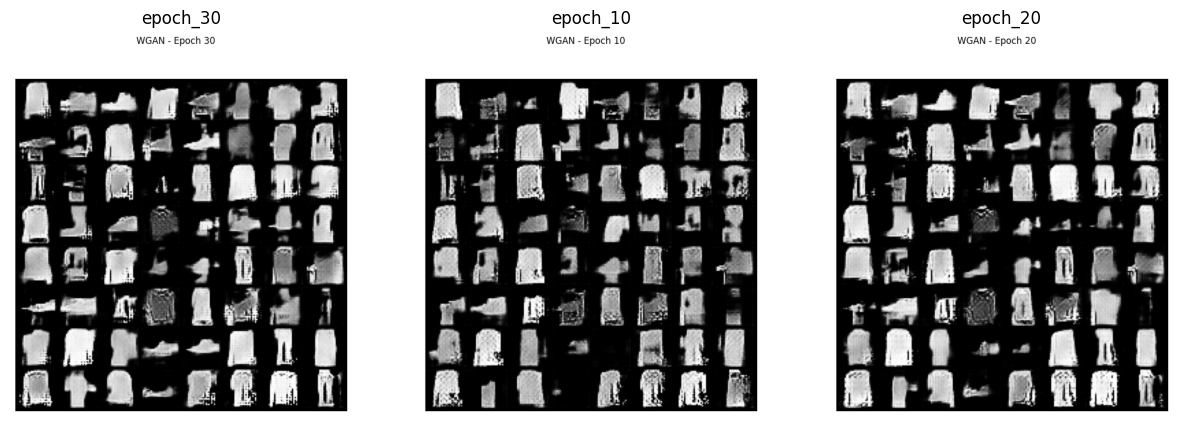

In [40]:

show_saved_images(save_dir="generated_images")